# κ-GNAR on power-law networks

This notebook explores the `KappaGNAR` model. It's a playground: change the parameters in the **Settings** cell and re-run everything.

## The model
On an unweighted, undirected graph with no isolated nodes, the model for node $i$ is

$$X_{i,t} - \mu_i = \alpha\,(X_{i,t-1}-\mu_i) + \beta\, d_i^{-\kappa} \sum_{j \in \mathcal N(i)} (X_{j,t-1}-\mu_j) + \varepsilon_{i,t}, \qquad \varepsilon_t \sim N(0, \sigma^2 I),$$

where $d_i$ is node $i$'s degree and $\kappa \in [0,1]$ controls how the neighbour sum is normalised.
- $\kappa = 1$: the neighbour **average**, i.e. the standard global GNAR(1, [1]).
- $\kappa = 0$: the raw neighbour **sum**.

**Spectral normalisation (the default parametrisation).** The model is written in terms of $b = \beta\,\rho_\kappa$, where $\rho_\kappa$ is the spectral radius of $D^{-\kappa}A$:

$$X_t - \mu = \Phi\,(X_{t-1}-\mu) + \varepsilon_t, \qquad \Phi = \alpha I + b\,\frac{D^{-\kappa}A}{\rho_\kappa}.$$

The network part of $\Phi$ then has spectral radius exactly $|b|$, so $b$ is on the same scale for every $\kappa$ and every graph.

**Computing $\rho_\kappa$.** $D^{-\kappa}A$ is similar to the symmetric matrix $D^{-\kappa/2}AD^{-\kappa/2}$. So its eigenvalues are real, and a symmetric eigensolver gives the extreme ones, $\mu_{\min}$ and $\rho_\kappa$.

**Stationarity (exact).** The eigenvalues of $\Phi$ are $\alpha + b\,\mu/\rho_\kappa$, with $\mu \in [\mu_{\min}, \rho_\kappa]$. So the process is stationary if and only if

$$|\alpha + b| < 1 \quad\text{and}\quad |\alpha + b\,\mu_{\min}/\rho_\kappa| < 1.$$

$|\alpha| + |b| < 1$ is always sufficient. It is also necessary when the graph has a bipartite component.

## What `KappaGNAR` provides (so far)

| Method / attribute | What it does |
|---|---|
| `KappaGNAR(A, alpha, b, kappa, *, beta=None, mean=0, sigma_2=1, names=None)` | Build from known parameters. Pass `b` or `beta`. |
| `.alpha, .b, .kappa, .beta, .rho, .mu, .sigma_2, .names, .degrees` | Parameters and graph information |
| `.phi()`, `.to_var()` | Sparse VAR(1) coefficient matrix / equivalent (dense) `VAR` object |
| `.is_stationary()`, `.phi_spectral_radius()`, `.is_regular()` | Exact stationarity check and spectral radius of $\Phi$ (closed form); regular graph (κ then can't be estimated) |
| `.simulate(n, sigma_2=None, burn_in=50, as_frame=False)` | Simulated path, `(n, d)` |
| `.predict(ts, h)` | 1- to h-step forecasts (same conventions as `GNAR.predict`) |
| `.compute_autocov_mats(k)`, `.compute_autocorr_mats(k)`, `.marginal_variances()` | Theoretical second moments, in closed form (see §5) |
| `.clear_cache()` | Free the cached eigendecomposition used by the second moments |

### Performance
The graph is stored as a sparse matrix, so most operations scale with the number of edges $m$, not with $d^2$. Timings at $d = 10{,}000$:

| Operation | Method | Time |
|---|---|---|
| $\rho_\kappa$, $\mu_{\min}$ (model construction, stationarity) | Lanczos iterations (`eigsh`) on the sparse symmetric matrix | ~15 ms per κ |
| `simulate`, `predict` | one sparse matrix-vector product per step, $O(m)$ | 20,000 steps in ~2.5 s |
| Second moments | one dense symmetric eigendecomposition per κ (cached), then a few $d^3$ products | ~1 min per κ, then ~10 s per call |

Only the second moments are dense ($O(d^2)$ memory, 0.8 GB per matrix at 10,000 nodes). This notebook computes them once per κ, keeps only the parts it plots, and frees the rest.

Fitting κ by profile likelihood comes next.

In [1]:
import time
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm

from gnar import KappaGNAR
from gnar.kappa import kappa_spectrum_bounds
from gnar.utils.graphs import powerlaw_configuration_graph
from scipy.sparse.csgraph import shortest_path

T_START = time.perf_counter()

# ---- Plot style: thin marks, recessive axes; fixed categorical order (blue, orange, aqua) ----
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SEQ = ListedColormap(plt.cm.Blues(np.linspace(0.3, 1.0, 256)))      # sequential, one hue
DIV = "RdBu_r"                                                       # diverging, neutral midpoint
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 1.5,
    "legend.frameon": False, "axes.titlesize": 11, "axes.titleweight": "bold",
})
np.set_printoptions(precision=3, suppress=True)

## Settings
Everything below depends only on this cell. With `D_NODES = 10_000` the whole notebook takes about 4 minutes, almost all of it in the covariance section (one eigendecomposition per value of κ). With `D_NODES = 2_000` it takes about 10 seconds.

In [2]:
# Graph: erased configuration model with P(k) ~ k^-gamma on [k_min, k_max]
D_NODES = 10_000       # requested number of nodes
GAMMA = 2.5            # power-law exponent
K_MIN = 2              # minimum degree (2 keeps the giant component ~ the whole graph)
K_MAX = None           # None -> floor(sqrt(D_NODES)), the structural cutoff; D_NODES - 1 for uncapped
GRAPH_SEED = 1

# Model
ALPHA, B, KAPPA = 0.3, 0.6, 0.5
SIGMA_2 = 1.0
KAPPAS = [0.0, 0.5, 1.0]   # values compared in the plots (one colour each, fixed order)

# Simulation
N_STEPS = 500
N_LONG = 20_000        # length of the long run used to check theory against simulation
SIM_SEED = 42

# Plot sizes (these keep the plots readable and the notebook fast on large graphs)
FULL_LAYOUT_MAX = 3_000   # draw the whole graph only up to this many nodes
N_HEATMAP = 300           # correlation heatmaps show the N_HEATMAP highest-degree nodes
N_DIST_SOURCES = 300      # correlation vs distance uses BFS from this many random source nodes
N_COMPARE = 300           # theory vs simulation is compared on this many random nodes

## 1. The graph
`powerlaw_configuration_graph` runs four steps:
1. Sample degrees from a discrete power law.
2. Pair "edge stubs" (half-edges) at random with `networkx.configuration_model`.
3. Remove self-loops and collapse multi-edges (the *erased* configuration model).
4. Keep the largest connected component.

The `info` dictionary reports how much was removed.

In [3]:
G, info = powerlaw_configuration_graph(D_NODES, gamma=GAMMA, k_min=K_MIN, k_max=K_MAX, seed=GRAPH_SEED, return_info=True)
A = nx.to_scipy_sparse_array(G, nodelist=range(G.number_of_nodes()), format="csr")   # sparse adjacency matrix
deg = np.asarray(A.sum(axis=1)).ravel()
d = A.shape[0]
print(info)
print(f"degrees: min={deg.min():.0f}, median={np.median(deg):.0f}, mean={deg.mean():.2f}, max={deg.max():.0f}")

{'n_requested': 10000, 'n_nodes': 10000, 'n_edges': 20719, 'self_loops_removed': 8, 'multi_edges_removed': 25, 'nodes_removed': 0}
degrees: min=1, median=2, mean=4.14, max=94


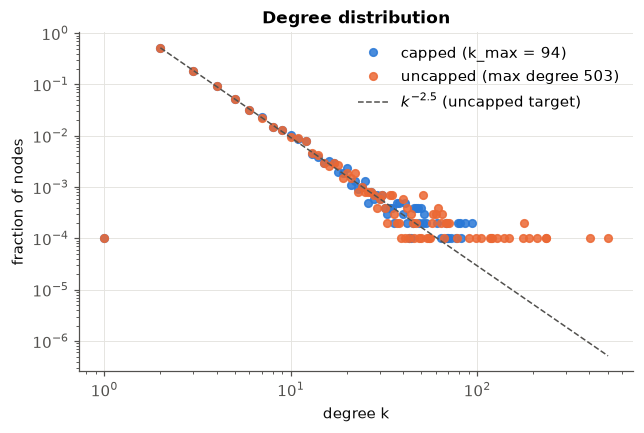

In [4]:
# Degree distribution: capped (structural cutoff) vs uncapped, with the target k^-gamma law
G_unc = powerlaw_configuration_graph(D_NODES, gamma=GAMMA, k_min=K_MIN, k_max=D_NODES - 1, seed=GRAPH_SEED)
deg_unc = np.array([k for _, k in G_unc.degree])

fig, ax = plt.subplots(figsize=(6.5, 4))
for degs, label, color in [(deg, f"capped (k_max = {int(deg.max())})", BLUE),
                           (deg_unc, f"uncapped (max degree {deg_unc.max()})", ORANGE)]:
    k, counts = np.unique(degs, return_counts=True)
    ax.loglog(k, counts / counts.sum(), "o", ms=5, color=color, label=label, alpha=0.85)
k_line = np.arange(K_MIN, deg_unc.max() + 1)
law = k_line ** -GAMMA / np.sum(k_line ** -GAMMA)
ax.loglog(k_line, law, color=MUTED, lw=1, ls="--", label=fr"$k^{{-{GAMMA}}}$ (uncapped target)")
ax.set_xlabel("degree k"); ax.set_ylabel("fraction of nodes")
ax.set_title("Degree distribution")
ax.legend()
plt.show()

In [5]:
# The whole graph: node size and colour by degree (skipped on large graphs: the layout costs O(d^2) per iteration
# and the drawing would be unreadable anyway)
if d <= FULL_LAYOUT_MAX:
    t0 = time.perf_counter()
    pos = nx.spring_layout(G, seed=0, k=1.5 / np.sqrt(d), iterations=100)
    print(f"layout: {time.perf_counter() - t0:.1f}s")
    fig, ax = plt.subplots(figsize=(8, 8))
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=MUTED, alpha=0.15, width=0.5)
    nodes = nx.draw_networkx_nodes(G, pos, ax=ax, node_size=4 + 6 * deg, node_color=deg, cmap=SEQ,
                                   edgecolors="white", linewidths=0.4)
    fig.colorbar(nodes, ax=ax, shrink=0.6, label="degree")
    ax.set_title(f"Power-law configuration graph: {d} nodes, {G.number_of_edges()} edges")
    ax.axis("off")
    plt.show()
else:
    print(f"Full graph drawing skipped: {d} nodes > FULL_LAYOUT_MAX = {FULL_LAYOUT_MAX}. See the hub neighbourhood below.")

Full graph drawing skipped: 10000 nodes > FULL_LAYOUT_MAX = 3000. See the hub neighbourhood below.


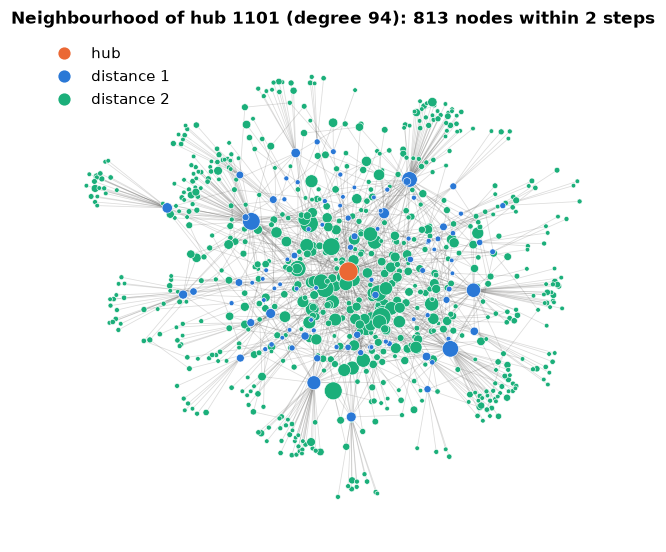

In [6]:
# Neighbourhood of the largest hub (radius 2)
hub = int(np.argmax(deg))
ego = nx.ego_graph(G, hub, radius=2)
if ego.number_of_nodes() > 1500:          # keep the drawing readable on large graphs
    ego = nx.ego_graph(G, hub, radius=1)
dist_hub = nx.single_source_shortest_path_length(ego, hub)
fig, ax = plt.subplots(figsize=(7, 6))
p_ego = nx.spring_layout(ego, seed=1)
nx.draw_networkx_edges(ego, p_ego, ax=ax, edge_color=MUTED, alpha=0.2, width=0.5)
size = lambda n: 6 + 150 * deg[n] / deg.max()          # node area proportional to degree, capped
labels = {0: "hub", 1: "distance 1", 2: "distance 2"}
colors = {0: ORANGE, 1: BLUE, 2: AQUA}
for r in (2, 1, 0):                                     # draw the hub last, on top
    nl = [n for n, dist in dist_hub.items() if dist == r]
    if nl:
        nx.draw_networkx_nodes(ego, p_ego, nodelist=nl, ax=ax, node_size=[size(n) for n in nl],
                               node_color=colors[r], edgecolors="white", linewidths=0.4)
handles = [plt.Line2D([], [], marker="o", ls="", ms=7, color=colors[r], label=labels[r])
           for r in sorted(set(dist_hub.values()))]
ax.legend(handles=handles, loc="upper left"); ax.axis("off")
ax.set_title(f"Neighbourhood of hub {hub} (degree {deg[hub]:.0f}): {ego.number_of_nodes()} nodes "
             f"within {max(dist_hub.values())} steps")
plt.show()

## 2. Spectral normalisation and stationarity
$\rho_\kappa$ decreases smoothly from $\rho(A)$ at κ = 0 to 1 at κ = 1, where $D^{-1}A$ is the random-walk matrix. The ∞-norm $d_{\max}^{1-\kappa}$, the other normalisation we considered, is always at least $\rho_\kappa$. On heavy-tailed graphs it is much larger, because it is driven by the single biggest hub.

41 spectra (two extreme eigenvalues each, sparse Lanczos) in 0.59s


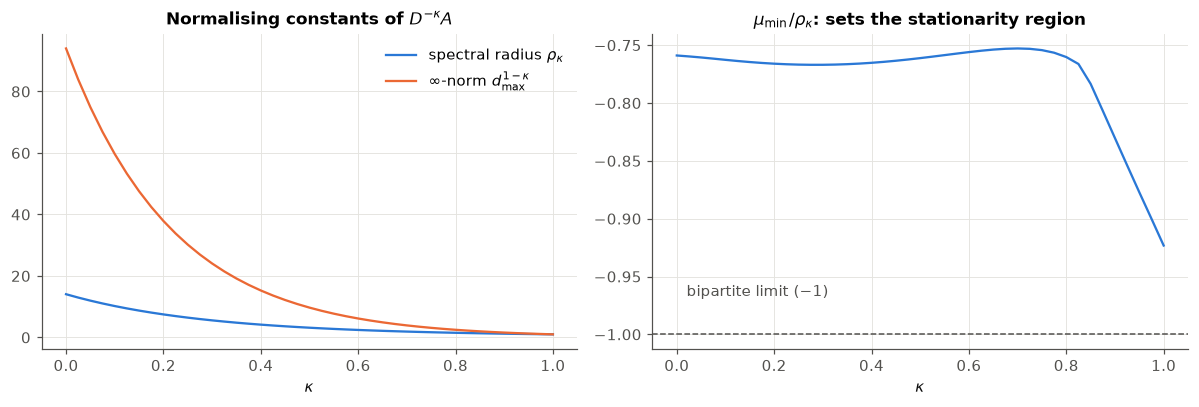

In [7]:
kgrid = np.linspace(0, 1, 41)
t0 = time.perf_counter()
bounds = np.array([kappa_spectrum_bounds(A, k) for k in kgrid])
print(f"{len(kgrid)} spectra (two extreme eigenvalues each, sparse Lanczos) in {time.perf_counter() - t0:.2f}s")
mu_min, rho = bounds[:, 0], bounds[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(kgrid, rho, color=BLUE, label=r"spectral radius $\rho_\kappa$")
ax[0].plot(kgrid, deg.max() ** (1 - kgrid), color=ORANGE, label=r"$\infty$-norm $d_{\max}^{1-\kappa}$")
ax[0].set_xlabel(r"$\kappa$"); ax[0].set_title(r"Normalising constants of $D^{-\kappa}A$"); ax[0].legend()
ax[1].plot(kgrid, mu_min / rho, color=BLUE)
ax[1].axhline(-1, color=MUTED, lw=1, ls="--")
ax[1].text(0.02, -0.97, "bipartite limit (−1)", color=MUTED, va="bottom")
ax[1].set_xlabel(r"$\kappa$"); ax[1].set_title(r"$\mu_{\min}/\rho_\kappa$: sets the stationarity region")
plt.tight_layout(); plt.show()

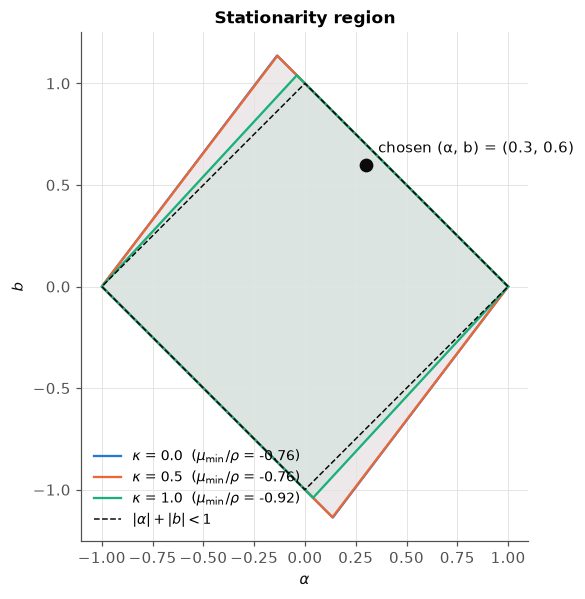

In [8]:
# Exact stationarity region in the (alpha, b) plane for several kappa, versus the diamond |alpha| + |b| < 1
def region_vertices(c):
    # Intersection of the strips |alpha + b| < 1 and |alpha + c b| < 1 (c = mu_min / rho): a parallelogram
    verts = []
    for s1, s2 in [(1, 1), (1, -1), (-1, -1), (-1, 1)]:
        b = (s1 - s2) / (1 - c)
        verts.append((s1 - b, b))
    return np.array(verts + verts[:1])

fig, ax = plt.subplots(figsize=(6, 6))
for kappa, color in zip(KAPPAS, [BLUE, ORANGE, AQUA]):
    lo, hi = kappa_spectrum_bounds(A, kappa)
    v = region_vertices(lo / hi)
    ax.fill(v[:, 0], v[:, 1], color=color, alpha=0.08)
    ax.plot(v[:, 0], v[:, 1], color=color, label=fr"$\kappa$ = {kappa}  ($\mu_{{\min}}/\rho$ = {lo / hi:.2f})")
diamond = np.array([(1, 0), (0, 1), (-1, 0), (0, -1), (1, 0)])
ax.plot(diamond[:, 0], diamond[:, 1], color=INK, lw=1, ls="--", label=r"$|\alpha| + |b| < 1$")
ax.plot(ALPHA, B, "o", color=INK, ms=8)
ax.annotate(f"chosen (α, b) = ({ALPHA}, {B})", (ALPHA, B), xytext=(8, 8), textcoords="offset points", color=INK)
ax.set_xlabel(r"$\alpha$"); ax.set_ylabel(r"$b$"); ax.set_aspect("equal")
ax.set_title("Stationarity region")
ax.legend(loc="lower left", fontsize=9)
plt.show()

## 3. The model

In [9]:
model = KappaGNAR(A, alpha=ALPHA, b=B, kappa=KAPPA, sigma_2=SIGMA_2)
print(repr(model))
print(model)
print("stationary:", model.is_stationary(), "| regular graph:", model.is_regular())
print("spectral radius of Phi (closed form):", round(model.phi_spectral_radius(), 4))

KappaGNAR(d=10000, alpha=0.3, b=0.6, kappa=0.5)
Kappa-GNAR(1, [1]) Model (spectral normalisation)
Graph with 10000 nodes and 20719 edges; degrees from 1 to 94 (mean 4.14)
Parameters:
alpha                     0.300000
b                         0.600000
kappa                     0.500000
beta (= b / rho_kappa)    0.190088
rho_kappa                 3.156428
sigma_2                   1.000000
Mean: 0 (all nodes)

stationary: True | regular graph: False
spectral radius of Phi (closed form): 0.9


**How strongly each node is pulled by its neighbours.** Row $i$ of the network part of $\Phi$ sums to $(b/\rho_\kappa)\,d_i^{1-\kappa}$, which is the total weight node $i$ puts on its neighbours.
- κ = 1: every node gets the same total, $b$.
- κ < 1: hubs get more, and leaves get less, than under κ = 1.

This one fact explains most of the covariance patterns below.

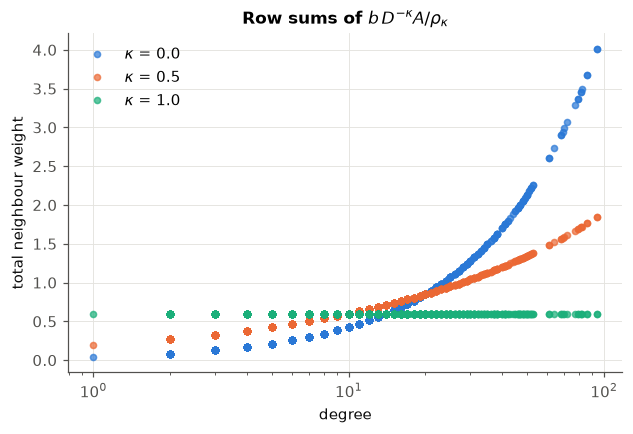

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for kappa, color in zip(KAPPAS, [BLUE, ORANGE, AQUA]):
    m = KappaGNAR(A, alpha=ALPHA, b=B, kappa=kappa)
    row_sums = np.asarray(m.phi().sum(axis=1)).ravel() - ALPHA      # phi() is sparse
    ax.plot(deg, row_sums, "o", ms=4, color=color, alpha=0.7, label=fr"$\kappa$ = {kappa}")
ax.set_xscale("log"); ax.set_xlabel("degree"); ax.set_ylabel("total neighbour weight")
ax.set_title(r"Row sums of $b\,D^{-\kappa}A/\rho_\kappa$")
ax.legend(); plt.show()

## 4. Simulated time series

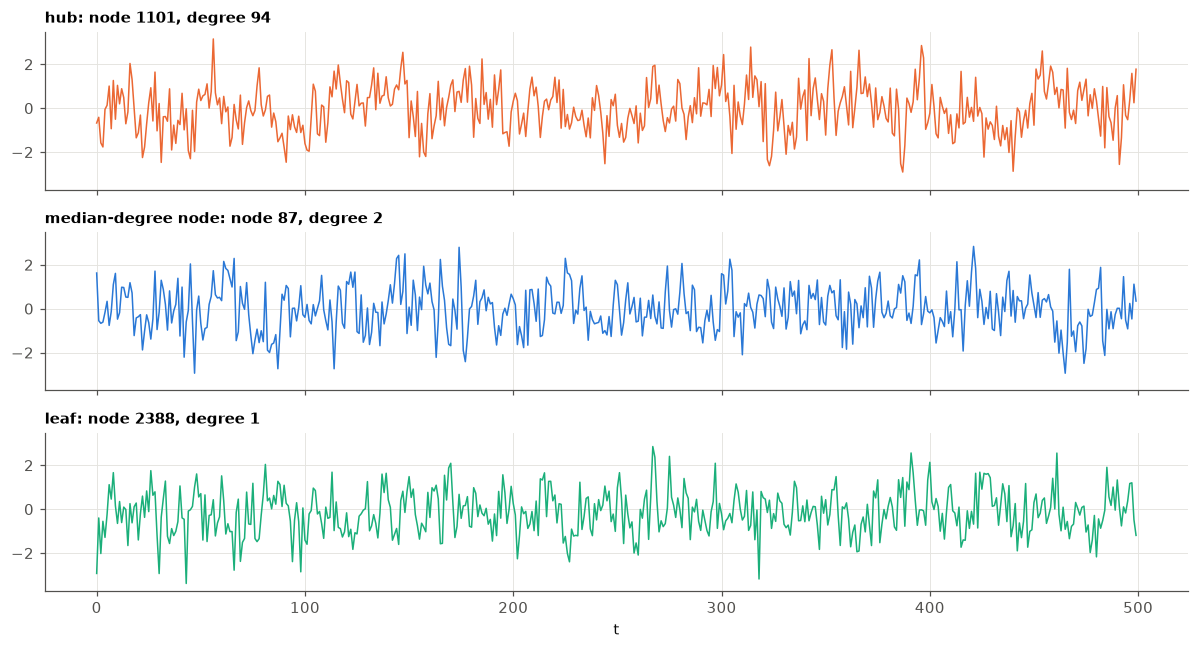

In [11]:
np.random.seed(SIM_SEED)
ts = model.simulate(N_STEPS, as_frame=True)
order = np.argsort(deg)[::-1]                       # nodes sorted by degree, hubs first
leaf = int(order[-1]); mid = int(order[len(order) // 2])
picks = [(hub, "hub", ORANGE), (mid, "median-degree node", BLUE), (leaf, "leaf", AQUA)]

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True, sharey=True)
for ax, (node, label, color) in zip(axes, picks):
    ax.plot(ts.index, ts[node], color=color, lw=1)
    ax.set_title(f"{label}: node {node}, degree {deg[node]:.0f}", loc="left", fontsize=10)
axes[-1].set_xlabel("t")
plt.tight_layout(); plt.show()

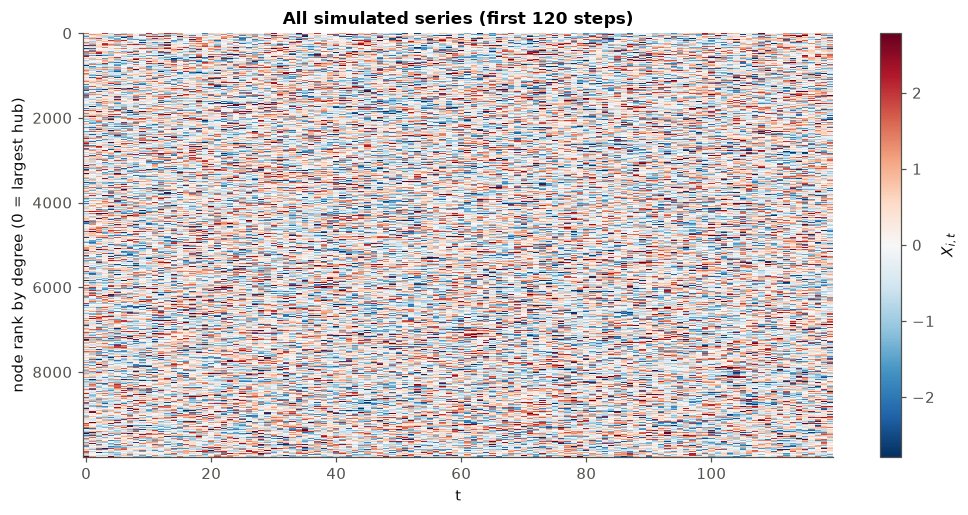

In [12]:
# All nodes at once over a 120-step window: time x node, nodes sorted by degree (hubs at the top)
window = ts.to_numpy()[:120, order].T
fig, ax = plt.subplots(figsize=(11, 5))
vmax = np.quantile(np.abs(window), 0.99)
im = ax.imshow(window, aspect="auto", cmap=DIV, norm=TwoSlopeNorm(0, -vmax, vmax), interpolation="nearest")
fig.colorbar(im, ax=ax, label=r"$X_{i,t}$")
ax.set_xlabel("t"); ax.set_ylabel("node rank by degree (0 = largest hub)")
ax.set_title("All simulated series (first 120 steps)"); ax.grid(False)
plt.show()

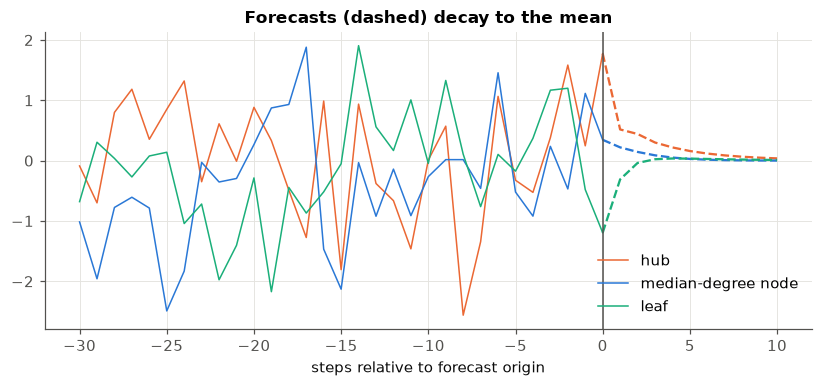

In [13]:
# Forecasting: 1..10-step forecasts from the last observation, with the observed path for the three picked nodes
h = 10
fc = model.predict(ts.iloc[[-1]], h=h)              # (h, d) DataFrame indexed 1..h
fig, ax = plt.subplots(figsize=(9, 3.5))
for node, label, color in picks:
    ax.plot(range(-30, 1), ts[node].iloc[-31:], color=color, lw=1, label=label)
    ax.plot(range(0, h + 1), np.r_[ts[node].iloc[-1], fc[node]], color=color, lw=1.5, ls="--")
ax.axvline(0, color=MUTED, lw=1)
ax.set_xlabel("steps relative to forecast origin"); ax.set_title("Forecasts (dashed) decay to the mean")
ax.legend(); plt.show()

## 5. Covariance structure
The theoretical autocovariances are $\Gamma(k) = \operatorname{Cov}(X_t, X_{t-k})$. Write $\Phi = D^{-\kappa/2} M D^{\kappa/2}$, with $M = \alpha I + \frac{b}{\rho_\kappa}S$ symmetric and $S = D^{-\kappa/2}AD^{-\kappa/2} = U\,\mathrm{diag}(s)\,U^\top$. Then summing $\Gamma(0) = \sigma^2\sum_k \Phi^k\Phi^{k\top}$ gives the closed form

$$\Gamma(0) = \sigma^2\, D^{-\kappa/2}\, U \Big[ (U^\top D^{\kappa} U) \oslash (1 - \lambda\lambda^\top) \Big] U^\top D^{-\kappa/2}, \qquad \lambda = \alpha + \tfrac{b}{\rho_\kappa}\, s,$$

where $\oslash$ is element-wise division, and then $\Gamma(k) = \Phi\,\Gamma(k-1)$ with sparse products. The cost is one symmetric eigendecomposition, which depends only on the graph and κ and is cached by the model, plus a few dense matrix products.

The next cell computes $\Gamma(0)$ and $\Gamma(1)$ **once per κ**. It keeps only what the plots need, then frees the $d \times d$ matrices:
- the variances;
- the correlations among the `N_HEATMAP` largest hubs;
- the correlation rows for `N_DIST_SOURCES` random source nodes;
- the covariances of `N_COMPARE` random nodes, for the theory-vs-simulation check.

In [14]:
rng = np.random.default_rng(0)
hubs = order[:N_HEATMAP]                                        # highest-degree nodes, in degree order
sources = rng.choice(d, size=min(N_DIST_SOURCES, d), replace=False)
compare = np.sort(rng.choice(d, size=min(N_COMPARE, d), replace=False))

moments = {}
for kappa in sorted(set(KAPPAS) | {KAPPA}):
    t0 = time.perf_counter()
    m = KappaGNAR(A, alpha=ALPHA, b=B, kappa=kappa, sigma_2=SIGMA_2)
    G01 = m.compute_autocov_mats(1)                              # (2, d, d), dense
    sd = np.sqrt(np.diag(G01[0]))
    moments[kappa] = {
        "var": sd ** 2,
        "R_hubs": G01[:, hubs][:, :, hubs] / np.outer(sd[hubs], sd[hubs]),
        "R_sources": G01[:, sources, :] / np.outer(sd[sources], sd)[None],
        "G_compare": G01[:, compare][:, :, compare],
    }
    del G01, m                                                   # frees the dense matrices and the cached eigendecomposition
    print(f"kappa = {kappa}: second moments in {time.perf_counter() - t0:.1f}s")

kappa = 0.0: second moments in 72.5s


kappa = 0.5: second moments in 72.5s


kappa = 1.0: second moments in 72.6s


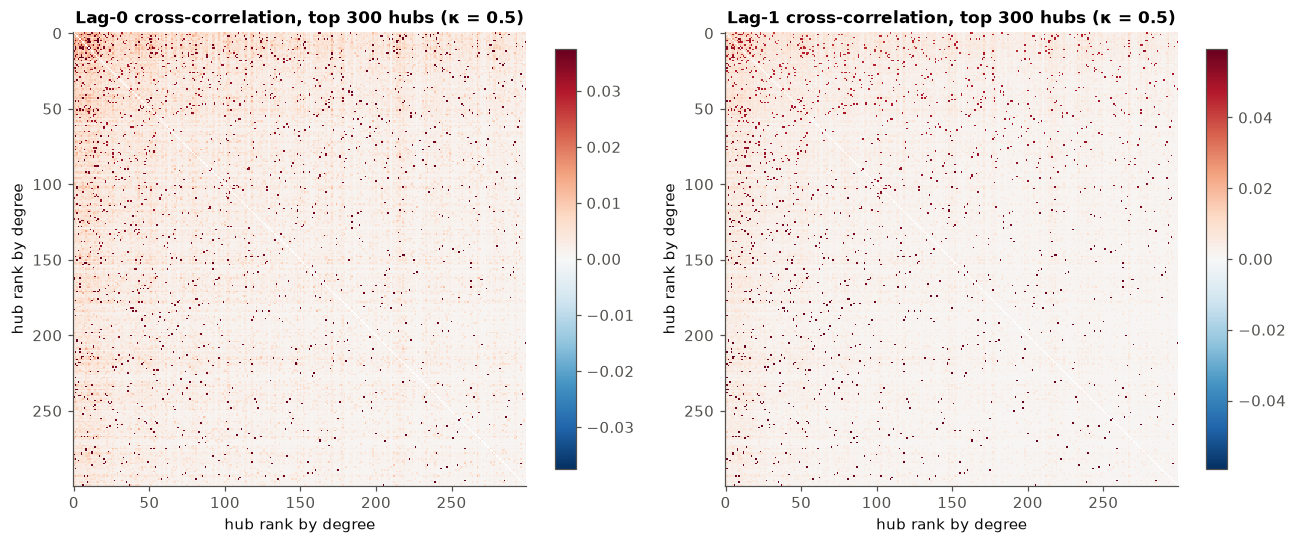

In [15]:
# Lag-0 and lag-1 cross-correlations among the N_HEATMAP largest hubs (diagonal hidden), for the chosen kappa
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, k in zip(axes, [0, 1]):
    M = moments[KAPPA]["R_hubs"][k].copy()
    np.fill_diagonal(M, np.nan)
    lim = np.nanquantile(np.abs(M), 0.995)
    im = ax.imshow(M, cmap=DIV, norm=TwoSlopeNorm(0, -lim, lim), interpolation="nearest")
    ax.set_title(f"Lag-{k} cross-correlation, top {len(hubs)} hubs (κ = {KAPPA})")
    ax.set_xlabel("hub rank by degree"); ax.set_ylabel("hub rank by degree"); ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

The darkest isolated dots are pairs of hubs that are direct neighbours. They go beyond the colour limit.

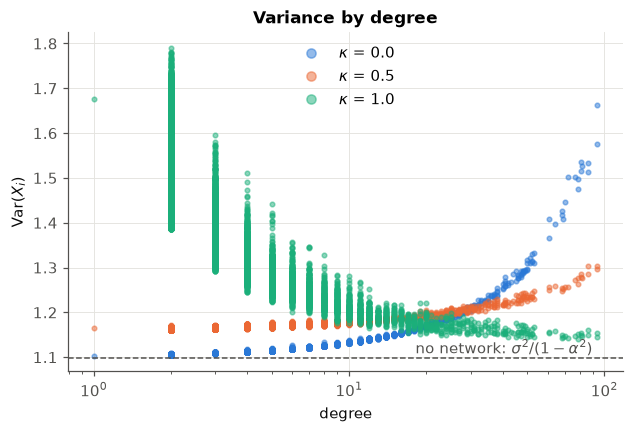

In [16]:
# Marginal variance against degree, for several kappa (same alpha, b, sigma_2)
fig, ax = plt.subplots(figsize=(6.5, 4))
for kappa, color in zip(KAPPAS, [BLUE, ORANGE, AQUA]):
    ax.plot(deg, moments[kappa]["var"], "o", ms=3, color=color, alpha=0.5, label=fr"$\kappa$ = {kappa}")
ax.axhline(SIGMA_2 / (1 - ALPHA ** 2), color=MUTED, lw=1, ls="--")
ax.text(deg.max(), SIGMA_2 / (1 - ALPHA ** 2), r"no network: $\sigma^2/(1-\alpha^2)$ ", color=MUTED, va="bottom", ha="right")
ax.set_xscale("log"); ax.set_xlabel("degree"); ax.set_ylabel(r"Var$(X_i)$")
ax.set_title("Variance by degree"); ax.legend(markerscale=2); plt.show()

Two effects pull in opposite directions.
- **Total weight.** Node $i$'s total neighbour weight is $(b/\rho_\kappa)\,d_i^{1-\kappa}$, so for κ < 1 hubs lean harder on their neighbours.
- **Averaging.** When neighbours are close to independent, the neighbour term has variance $\operatorname{Var}(d_i^{-\kappa}\sum_{j} X_j) \approx d_i^{1-2\kappa}\, v$, where $v$ is a typical node variance.

Combining them:
- **κ = 1 (average):** a leaf "averages" a single neighbour and takes on all of its noise, while a hub's average over many neighbours cancels most of it. So **leaves have the largest variance**.
- **κ = 0 (sum):** hubs add up many neighbours, so **hubs have the largest variance**.
- **κ = 1/2:** the exponent $1 - 2\kappa$ vanishes, so the neighbour input has (roughly) the same variance at every degree. That's the flattest of the three curves.

Because $b$ is spectrally normalised, the network's dominant mode has the same strength ($|b|$) for every κ. κ only changes how that strength is spread across nodes.

BFS from 300 sources: 0.25s


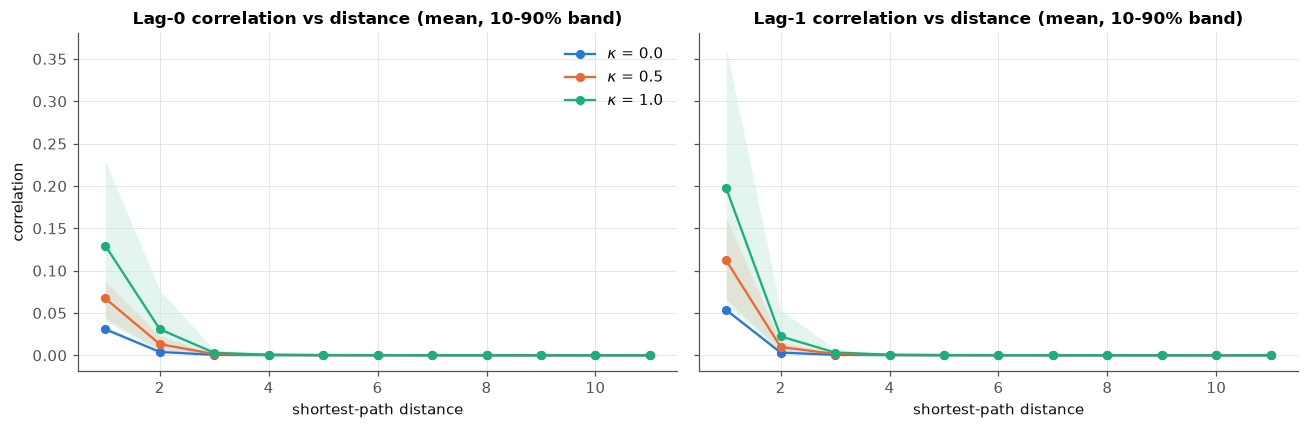

In [17]:
# Correlation against shortest-path distance (lag 0 and lag 1): BFS from the sampled source nodes, in C via scipy
t0 = time.perf_counter()
dist_src = shortest_path(A, unweighted=True, directed=False, indices=sources).astype(int)   # (n_sources, d)
print(f"BFS from {len(sources)} sources: {time.perf_counter() - t0:.2f}s")
not_self = dist_src > 0
dd = dist_src[not_self]
xs = np.arange(1, dd.max() + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for kappa, color in zip(KAPPAS, [BLUE, ORANGE, AQUA]):
    for ax, lag in zip(axes, [0, 1]):
        r = moments[kappa]["R_sources"][lag][not_self]
        stats = np.array([(r[dd == x].mean(), *np.quantile(r[dd == x], [0.1, 0.9])) for x in xs])
        ax.plot(xs, stats[:, 0], "o-", color=color, ms=5, label=fr"$\kappa$ = {kappa}")
        ax.fill_between(xs, stats[:, 1], stats[:, 2], color=color, alpha=0.12, lw=0)
for ax, lag in zip(axes, [0, 1]):
    ax.set_xlabel("shortest-path distance"); ax.set_title(f"Lag-{lag} correlation vs distance (mean, 10-90% band)")
axes[0].set_ylabel("correlation"); axes[0].legend()
plt.tight_layout(); plt.show()

simulated 20000 steps on 10000 nodes in 2.5s


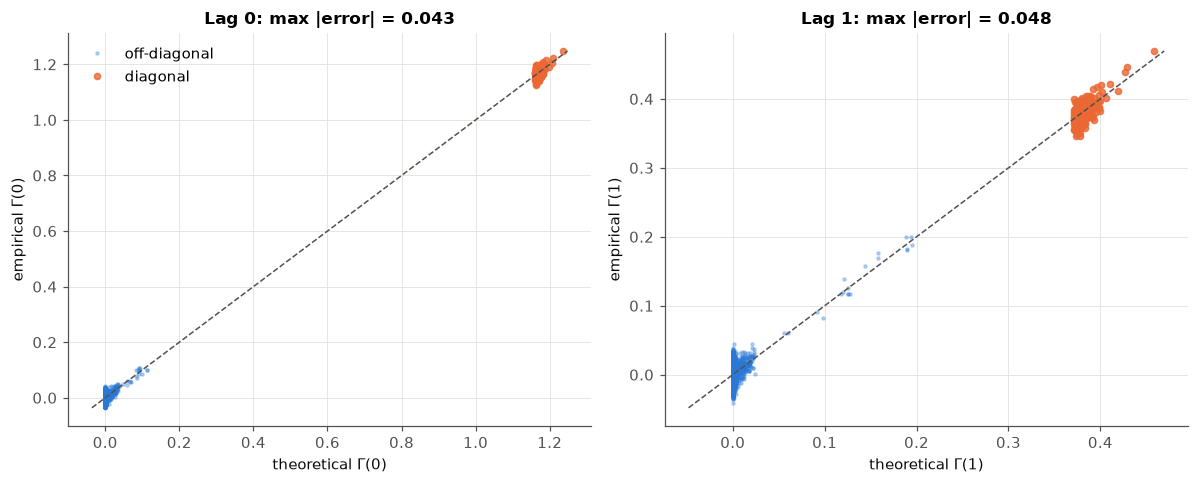

In [18]:
# Theory vs simulation on N_COMPARE random nodes: a long run, compared entry by entry
t0 = time.perf_counter()
np.random.seed(SIM_SEED + 1)
long = model.simulate(N_LONG)[:, compare]
print(f"simulated {N_LONG} steps on {d} nodes in {time.perf_counter() - t0:.1f}s")
lc = long - long.mean(axis=0)
emp = [lc.T @ lc / len(lc), lc[1:].T @ lc[:-1] / len(lc)]
theo = moments[KAPPA]["G_compare"]
iu = np.triu_indices(len(compare), 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, k in zip(axes, [0, 1]):
    ax.plot(theo[k][iu], emp[k][iu], "o", ms=2, color=BLUE, alpha=0.3, label="off-diagonal")
    ax.plot(np.diag(theo[k]), np.diag(emp[k]), "o", ms=4, color=ORANGE, alpha=0.8, label="diagonal")
    lim = [min(theo[k].min(), emp[k].min()), max(theo[k].max(), emp[k].max())]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.set_xlabel(f"theoretical Γ({k})"); ax.set_ylabel(f"empirical Γ({k})")
    ax.set_title(f"Lag {k}: max |error| = {np.abs(theo[k] - emp[k]).max():.3f}")
axes[0].legend()
plt.tight_layout(); plt.show()

## 6. Things to try
- **Heavier tails:** lower `GAMMA` (e.g. 2.1), or set `K_MAX = D_NODES - 1`. The degree spread grows, $\rho_\kappa$ and the ∞-norm drift further apart, and the curves for different κ separate more.
- **Near non-stationarity:** move `(ALPHA, B)` close to the edge of the stationarity region. Variances blow up, and they blow up first at the hubs when κ < 1.
- **Negative network effects:** try `B < 0`. On non-bipartite graphs the stationarity region is not symmetric in $b$, as section 2 shows.
- **Graph size:** everything except the second moments scales with the number of edges. The second moments cost one $O(d^3)$ eigendecomposition per κ: about 1 min at 10,000 nodes (peak memory about 5 GB) and about 8 min at 20,000, where the dense matrices alone need about 20 GB of memory. Shrink `KAPPAS` to speed things up.
- **Regular graphs:** with `GAMMA` very large and `K_MIN = K_MAX = 3`, the graph is (nearly) regular, and κ stops mattering in the $b$ parametrisation.

In [19]:
print(f"Total runtime: {time.perf_counter() - T_START:.0f}s")

Total runtime: 223s
